In [155]:
from PIL import Image
import cv2
import numpy as np
import matplotlib.pyplot as plt
import copy
import os

In [156]:
# 1.
img_dir = "img/"
img_paths = os.listdir(img_dir)
img_paths.sort()
images = []

for path in img_paths:
    images.append(cv2.imread(img_dir+path))

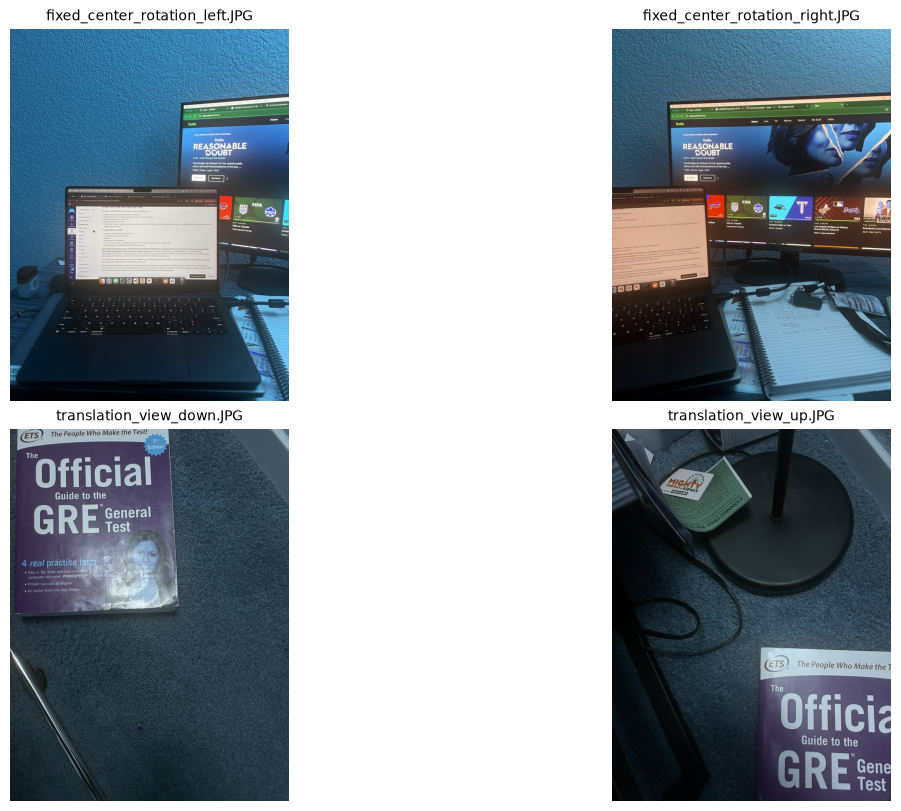

In [157]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()

for i in range(len(axes)):
    if i < 4:
        axes[i].imshow(images[i])
        axes[i].set_title(img_paths[i], fontsize=10)
        axes[i].axis('off')
    else:
        axes[i].axis('off')
        
plt.show()

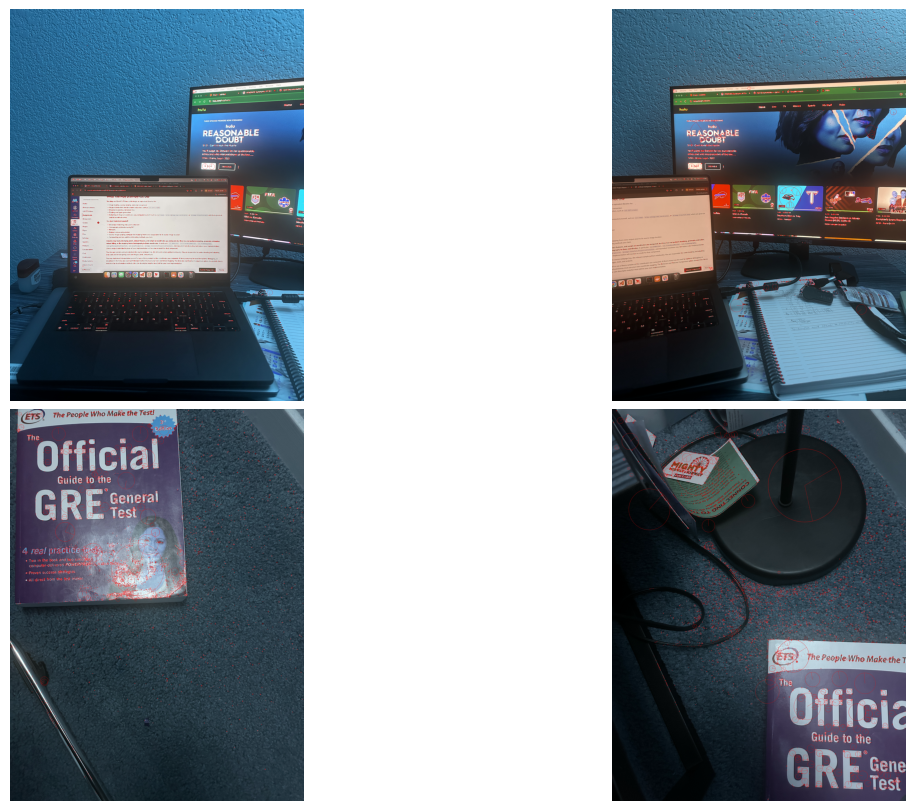

In [158]:
sift_ls = []
i = 0
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
axes = axes.flatten()
for img in images:

    sift = cv2.SIFT_create(nfeatures=8000)
    kp, desc = sift.detectAndCompute(img, None)
    sift_ls.append((kp,desc))

    keypoint_img = cv2.drawKeypoints(img, kp, outImage=None, color=(255,0,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    
    axes[i].imshow(keypoint_img)
    axes[i].axis('off')
    i+=1
            
plt.show()

In [161]:
#2.
sift1 = sift_ls[0][1]
sift2 = sift_ls[1][1]
result = []
for i in range(len(sift1)):
    best = [np.inf, i, -1]
    second = [np.inf, i, -1]
    for j in range(len(sift2)):
        dist = np.linalg.norm(sift1[i] - sift2[j])
        if dist < best[0]:
            second = best
            best = [dist, i, j]
        elif dist < second[0]:
            second = [dist, i, j]
    result.append([best, second])
good = [m for m, n in result if m[0] < 0.75 * n[0]]
print(len(result), "->", len(good))
# view = cv2.drawMatches(images[0], sift_ls[0][0], images[1], sift_ls[1][0], good, None, matchesThickness=5)
# plt.figure(figsize=(12, 6))
# plt.imshow(view)
# plt.axis('off')
# plt.show()

8000 -> 1145


< cv2.DMatch 0x14016c610>
8000 -> 1145


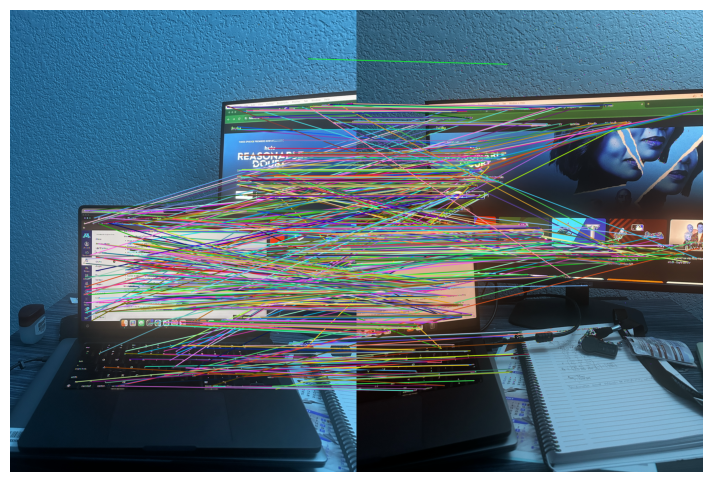

In [160]:
#2.
knn = cv2.BFMatcher().knnMatch(sift_ls[0][1], sift_ls[1][1], k=2)
print(knn[0][0])
good = [m for m, n in knn if m.distance < 0.75 * n.distance]
print(len(knn), "->", len(good))
view = cv2.drawMatches(images[0], sift_ls[0][0], images[1], sift_ls[1][0], good, None, matchesThickness=5)
plt.figure(figsize=(12, 6))
plt.imshow(view)
plt.axis('off')
plt.show()